# Online Food Delivery Exploratory Data Analysis & Prediction (EDAP)

Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

print("Libraries imported successfully!")

Libraries imported successfully!


Load Dataset

In [2]:
df = pd.read_csv("online food delivery dataset.csv")

print("Dataset loaded successfully!")
print("Shape:", df.shape)

Dataset loaded successfully!
Shape: (300, 14)


Understand the data

In [3]:
df.info()

print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

print("\nColumn names:")
print(df.columns.tolist())

df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 14 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Age                         300 non-null    int64  
 1   Gender                      300 non-null    object 
 2   Marital Status              300 non-null    object 
 3   Occupation                  300 non-null    object 
 4   Monthly Income              300 non-null    object 
 5   Educational Qualifications  300 non-null    object 
 6   Family size                 300 non-null    int64  
 7   Customer Type               300 non-null    object 
 8   latitude                    300 non-null    float64
 9   longitude                   300 non-null    float64
 10  Pin code                    300 non-null    int64  
 11  Output                      300 non-null    object 
 12  Feedback                    300 non-null    object 
 13  Unnamed: 13                 300 non

,Age,Family size,latitude,longitude,Pin code
count,300.000000,300.000000,300.000000,300.000000,300.000000
mean,24.550000,3.296667,12.974852,77.597099,560035.433333
std,2.921635,1.352066,0.043939,0.052407,29.922512
min,18.000000,1.000000,12.865200,77.484200,560001.000000
25%,23.000000,2.000000,12.944200,77.563700,560010.000000
50%,24.000000,3.000000,12.977000,77.587700,560024.500000
75%,26.000000,4.000000,12.998000,77.622700,560060.000000
max,33.000000,6.000000,13.102000,77.758200,560109.000000


Checking missing values

In [4]:
print("Missing values in each column:")
print(df.isnull().sum())

Missing values in each column:
Age                           0
Gender                        0
Marital Status                0
Occupation                    0
Monthly Income                0
Educational Qualifications    0
Family size                   0
Customer Type                 0
latitude                      0
longitude                     0
Pin code                      0
Output                        0
Feedback                      0
Unnamed: 13                   0
dtype: int64


Check Duplicate Rows

In [5]:
duplicate_count = df.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)

Number of duplicate rows: 24


Data Cleaning

In [6]:
df = df.drop(columns=["Unnamed: 13"])
df["Feedback"] = df["Feedback"].str.strip()
#Remove duplicate rows
df = df.drop_duplicates()


Check cleaned dataset

In [7]:
print("Cleaned dataset shape:", df.shape)
print("Remaining duplicate rows:", df.duplicated().sum())

Cleaned dataset shape: (276, 13)
Remaining duplicate rows: 0


Data Visualization

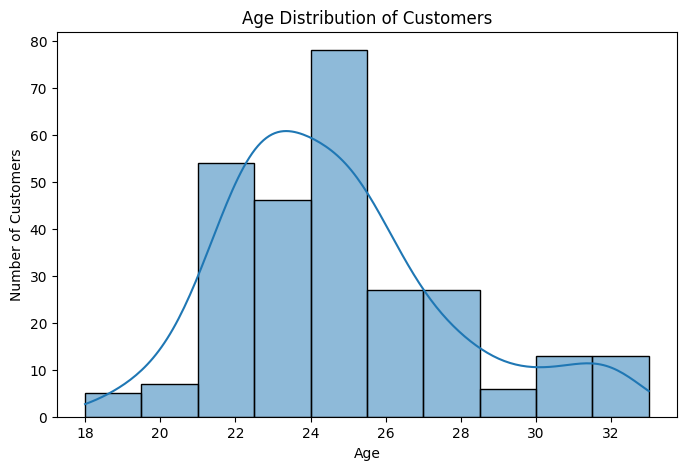

In [8]:
plt.figure(figsize=(8,5))

sns.histplot(df["Age"], bins=10, kde=True)

plt.title("Age Distribution of Customers")
plt.xlabel("Age")
plt.ylabel("Number of Customers")

plt.show()

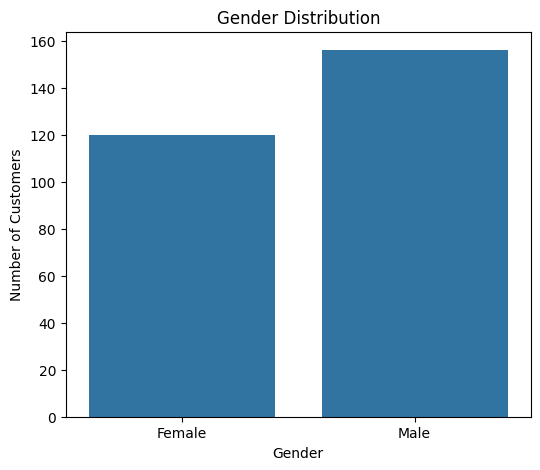

In [9]:
plt.figure(figsize=(6,5))

sns.countplot(data=df, x="Gender")

plt.title("Gender Distribution")
plt.xlabel("Gender")
plt.ylabel("Number of Customers")

plt.show()

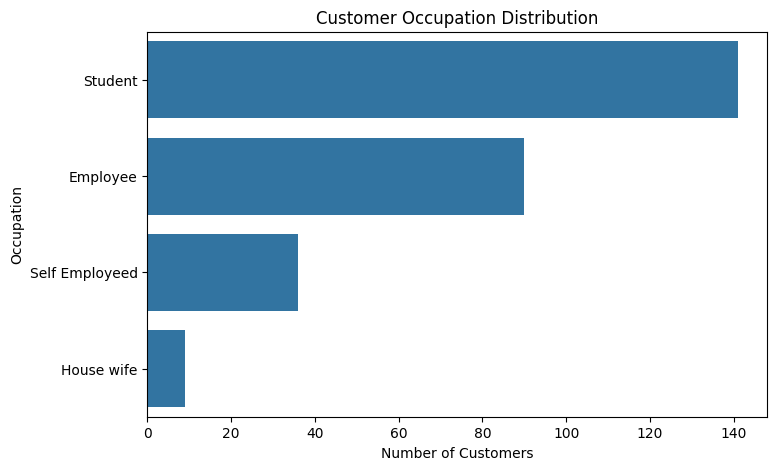

In [10]:
plt.figure(figsize=(8,5))

sns.countplot(
    data=df,
    y="Occupation",
    order=df["Occupation"].value_counts().index
)

plt.title("Customer Occupation Distribution")
plt.xlabel("Number of Customers")
plt.ylabel("Occupation")

plt.show()

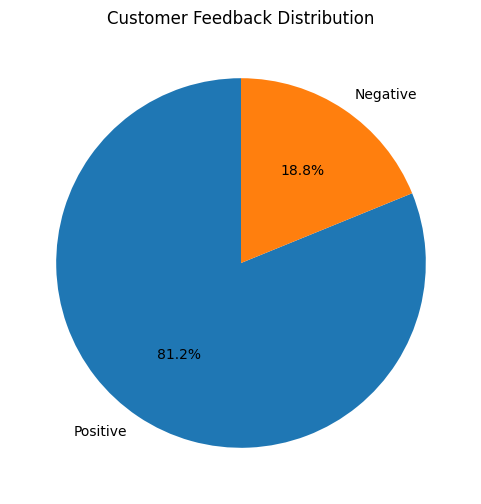

In [11]:
feedback_counts = df["Feedback"].value_counts()

plt.figure(figsize=(6,6))

plt.pie(
    feedback_counts.values,
    labels=feedback_counts.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Customer Feedback Distribution")

plt.show()

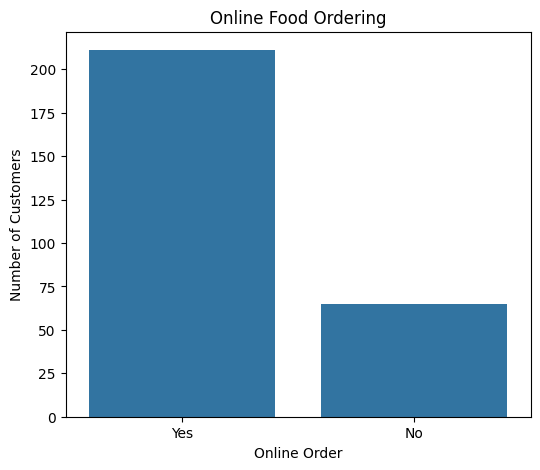

In [12]:
plt.figure(figsize=(6,5))

sns.countplot(data=df, x="Output")

plt.title("Online Food Ordering")
plt.xlabel("Online Order")
plt.ylabel("Number of Customers")

plt.show()

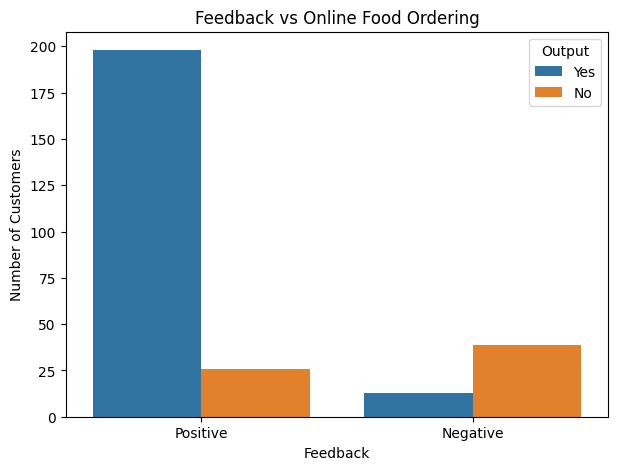

In [13]:
plt.figure(figsize=(7,5))

sns.countplot(
    data=df,
    x="Feedback",
    hue="Output"
)

plt.title("Feedback vs Online Food Ordering")
plt.xlabel("Feedback")
plt.ylabel("Number of Customers")

plt.show()

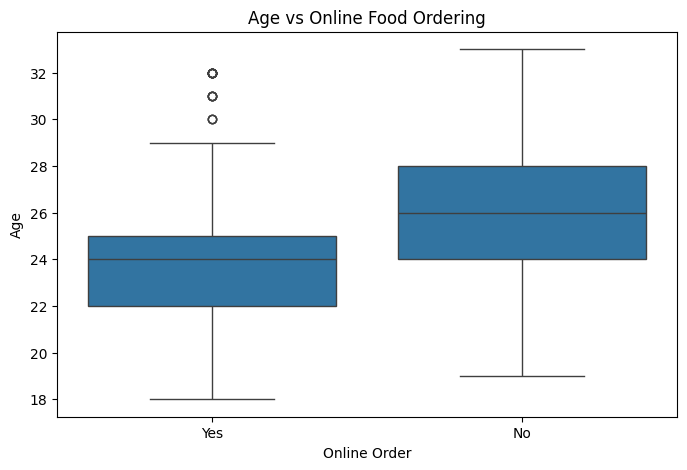

In [14]:
plt.figure(figsize=(8,5))

sns.boxplot(
    data=df,
    x="Output",
    y="Age"
)

plt.title("Age vs Online Food Ordering")
plt.xlabel("Online Order")
plt.ylabel("Age")

plt.show()

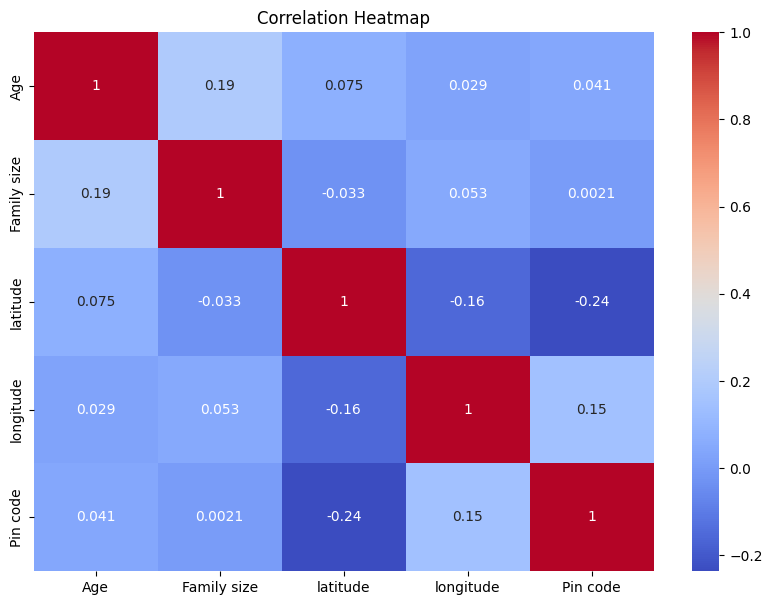

In [15]:
numeric_df = df.select_dtypes(include=np.number)

plt.figure(figsize=(10,7))

sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap="coolwarm"
)

plt.title("Correlation Heatmap")

plt.show()

In [16]:
print(df["Output"].value_counts())

Output
Yes    211
No      65
Name: count, dtype: int64


Convert categorical values into numbers

In [17]:
X = df.drop(columns=["Output"])
y = df["Output"]

X = pd.get_dummies(X, drop_first=True)

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (276, 22)
Target shape: (276,)


Train Test Split

In [18]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (220, 22)
Testing data: (56, 22)


Train Logistic Regression

In [19]:
model = LogisticRegression(max_iter=1000)

model.fit(X_train, y_train)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


Make predictions

In [20]:
y_pred = model.predict(X_test)

print("Predictions:")
print(y_pred)

Predictions:
['Yes' 'Yes' 'Yes' 'Yes' 'No' 'No' 'Yes' 'Yes' 'Yes' 'Yes' 'Yes' 'Yes'
 'Yes' 'No' 'Yes' 'Yes' 'Yes' 'Yes' 'Yes' 'Yes' 'Yes' 'Yes' 'Yes' 'Yes'
 'Yes' 'Yes' 'Yes' 'Yes' 'Yes' 'Yes' 'Yes' 'Yes' 'Yes' 'No' 'Yes' 'Yes'
 'Yes' 'Yes' 'No' 'Yes' 'Yes' 'No' 'Yes' 'Yes' 'Yes' 'No' 'Yes' 'Yes' 'No'
 'No' 'Yes' 'Yes' 'Yes' 'Yes' 'Yes' 'No']


Model Accuracy

In [21]:
accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", round(accuracy * 100, 2), "%")

Model Accuracy: 83.93 %


Classification Report

In [22]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

          No       0.70      0.54      0.61        13
         Yes       0.87      0.93      0.90        43

    accuracy                           0.84        56
   macro avg       0.78      0.73      0.75        56
weighted avg       0.83      0.84      0.83        56



Confusion Matrix

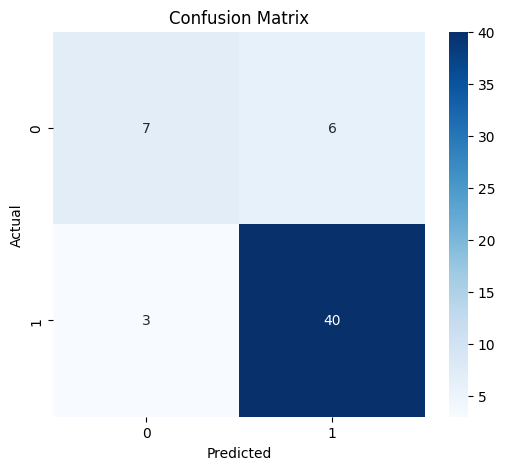

In [23]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6,5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

Final Conclusion

# Conclusion

In this project, we analyzed an online food delivery dataset using Python.

The project included:

1. Loading and understanding the dataset.
2. Checking missing values and duplicate records.
3. Cleaning unnecessary columns, duplicate records and inconsistent text.
4. Performing exploratory data analysis.
5. Creating different visualizations such as histograms, bar charts, pie charts, box plots and a correlation heatmap.
6. Using customer and behavioral information to predict online ordering.
7. Applying Logistic Regression as the machine learning algorithm.
8. Evaluating the model using accuracy, classification report and confusion matrix.

The analysis helped us understand customer characteristics and their relationship with online food ordering behavior.